<a href="https://colab.research.google.com/github/A-KOStov/Evlash-Valeria-2253/blob/main/Task03_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Популяция в линейно ухудшающейся среде**

In [6]:
import sympy as sp

In [2]:
t = sp.Symbol('t')
N = sp.Function('N')(t)
a, b, c = sp.symbols('a b c', positive=True)

In [3]:
eq = sp.Eq(N.diff(t), (a - b*t)*N - c*N**2)

In [4]:
sol = sp.dsolve(eq, N)
sp.pprint(sol)

                         ⎛    b⋅t⎞           
                       t⋅⎜a - ───⎟           
                         ⎝     2 ⎠           
                 2⋅√b⋅ℯ                      
N(t) = ──────────────────────────────────────
                         2                   
                        a                    
                        ───                  
                        2⋅b    ⎛√2⋅(a - b⋅t)⎞
       C₁⋅√b - √2⋅√π⋅c⋅ℯ   ⋅erf⎜────────────⎟
                               ⎝    2⋅√b    ⎠


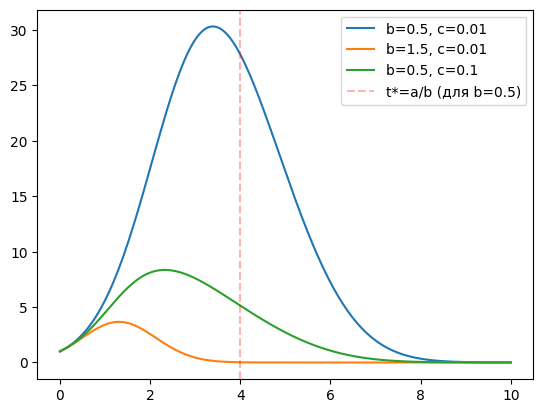

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

def model(N, t, a, b, c):
    return (a - b*t)*N - c*N**2

t = np.linspace(0, 10, 200)
a = 2.0
scenarios = [
    (0.5, 0.01, 'b=0.5, c=0.01'),
    (1.5, 0.01, 'b=1.5, c=0.01'),
    (0.5, 0.1, 'b=0.5, c=0.1'),
]

for b, c, label in scenarios:
    N0 = 1.0
    sol = odeint(model, N0, t, args=(a, b, c))
    plt.plot(t, sol, label=label)

plt.axvline(x=a/0.5, color='r', linestyle='--', alpha=0.3, label='t*=a/b (для b=0.5)')
plt.legend()
plt.show()